# 02_preprocess.py
## Split + preprocessing (tanpa data leakage).

### PENTING: 
Notebook lama mengimputasi median pada SELURUH dataset sebelum split,
ini menyebabkan data leakage (median test bocor ke train). Di sini kita lakukan
urutan yang benar:
  1. Split dulu (80/20, stratify)
  2. Imputer + scaler HANYA difit pada X_train, lalu transform X_test

Cara pakai:
  python scripts/02_preprocess.py


In [1]:
import json
import os

import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
BASE_DIR = os.path.dirname(os.path.abspath(''))
DATA_DIR = os.path.join(BASE_DIR, "data")
OUT_DIR = os.path.join(BASE_DIR, "output")
MODEL_DIR = os.path.join(BASE_DIR, "model")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

In [3]:
print(f"BASE_DIR: {BASE_DIR}")
print(f"DATA_DIR: {DATA_DIR}")
print(f"OUT_DIR: {OUT_DIR}")
print(f"MODEL_DIR: {MODEL_DIR}")

BASE_DIR: /home/krayza/Documents/Kuliah/Semester 5/Machine Learning/PJBL/PJBL di github/ML_Kelompok2_WaterPotability
DATA_DIR: /home/krayza/Documents/Kuliah/Semester 5/Machine Learning/PJBL/PJBL di github/ML_Kelompok2_WaterPotability/data
OUT_DIR: /home/krayza/Documents/Kuliah/Semester 5/Machine Learning/PJBL/PJBL di github/ML_Kelompok2_WaterPotability/output
MODEL_DIR: /home/krayza/Documents/Kuliah/Semester 5/Machine Learning/PJBL/PJBL di github/ML_Kelompok2_WaterPotability/model


In [4]:
TARGET_COL = "Potability"
TEST_SIZE = 0.2
RANDOM_STATE = 42

#### Part 1 -- Load Data

In [5]:
df = pd.read_csv(os.path.join(DATA_DIR, "water_potability.csv"))
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]
feature_cols = list(X.columns)


#### Part 2 -- Split Data

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape[0]} baris | Test: {X_test.shape[0]} baris")

Train: 2620 baris | Test: 656 baris


#### Part 3 -- imputer (median) + scaler

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), feature_cols),
    ],
    remainder="drop",
)

X_train_t = preprocessor.fit_transform(X_train)
X_test_t = preprocessor.transform(X_test)

# 03_train_evaluate.py
## Training 5 model + Threshold Tuning + Permutation Importance.

## Tujuan:
  1. Melatih 5 algoritma ML pada data train yang bersih (tanpa leakage).
  2. Membandingkan metrik evaluasi pada data test (Accuracy, Precision, Recall, F1, ROC-AUC).
  3. Menguji THRESHOLD TUNING (mengubah threshold dari 0.5 ke 0.6, 0.7, dll)
     khusus untuk mengurangi False Positive (FP) — air berbahaya dianggap layak.
  4. Menghitung Permutation Importance (pengaruh riil tiap fitur pada test set).

Cara pakai:
  python scripts/03_train_evaluate.py

In [8]:
import json
import os

import joblib
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

#### Part 1 : Definisi 5 Model yang dibandingkan

In [9]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier

from sklearn.calibration import CalibratedClassifierCV
models = {
    "SVM (RBF)": CalibratedClassifierCV(
        SVC(C=1.0, kernel="rbf", random_state=RANDOM_STATE),
        cv=5, method="sigmoid", ensemble=False
    ),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(random_state=RANDOM_STATE),
}

#### Part 2 : Cross Validation + Penentuan Model Terbaik ROC-AUC Based

In [10]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# Kandidat parameter tiap model (tanpa awalan; awalan ditambahkan otomatis di loop)
param_grids = {
    "SVM (RBF)": {
        "estimator__C": [0.1, 1, 10],
        "estimator__gamma": ["scale", 0.01, 0.1],
    },
    "Random Forest": {
        "n_estimators": [100, 300],
        "max_depth": [5, 10, None],
        "min_samples_leaf": [1, 5],
    },
    "Logistic Regression": {
        "C": [0.01, 0.1, 1, 10],
        "class_weight": [None, "balanced"],
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3, 4],
    },
    "KNN": {
        "n_neighbors": [5, 15, 31, 51],
        "weights": ["uniform", "distance"],
    },
}

tuning_rows = []
models_tuned = {}

for name, model in models.items():
    # preprocessing ikut di dalam pipeline, jadi dipelajari ulang di tiap fold (tanpa leakage)
    pipe = Pipeline([
        ("prep", clone(preprocessor)),
        ("model", clone(model)),
    ])
    grid = {f"model__{k}": v for k, v in param_grids[name].items()}

    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    search.fit(X_train, y_train)

    # buang awalan "model__" supaya bisa dipasang ke model polos
    best_params = {k.removeprefix("model__"): v for k, v in search.best_params_.items()}
    models_tuned[name] = clone(model).set_params(**best_params)

    tuning_rows.append({
        "Model": name,
        "Best CV ROC-AUC": round(search.best_score_, 4),
        "Parameter terbaik": best_params,
    })
    print(f"{name} selesai")

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best CV ROC-AUC", ascending=False)
tuning_df

SVM (RBF) selesai
Random Forest selesai
Gradient Boosting selesai
KNN selesai
Logistic Regression selesai


,Model,Best CV ROC-AUC,Parameter terbaik
0,SVM (RBF),0.7042,"{'estimator__C': 10, 'estimator__gamma': 0.1}"
1,Random Forest,0.6866,"{'max_depth': None, 'min_samples_leaf': 5, 'n_..."
3,KNN,0.6701,"{'n_neighbors': 51, 'weights': 'distance'}"
2,Gradient Boosting,0.6453,"{'learning_rate': 0.1, 'max_depth': 4, 'n_esti..."
4,Logistic Regression,0.4774,"{'C': 0.1, 'class_weight': None}"


In [20]:
print("Evaluasi model dengan cross-validation (CV) 5-fold Tanpa hyperparameter tuning (Pakai Parameter Default)")
cv_rows = []
oof_proba = {}   # prediksi out-of-fold tiap model

for name, model in models.items():
    fold_auc = []
    proba = np.zeros(len(y_train))

    for tr_idx, va_idx in cv.split(X_train, y_train):
        # preprocessing ikut dilatih ulang di dalam tiap fold, jadi tidak ada leakage
        pipe = make_pipeline(clone(preprocessor), clone(model))
        pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])

        p = pipe.predict_proba(X_train.iloc[va_idx])[:, 1]
        proba[va_idx] = p
        fold_auc.append(roc_auc_score(y_train.iloc[va_idx], p))

    oof_proba[name] = proba
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC (rata-rata)": round(np.mean(fold_auc), 4),
        "CV ROC-AUC (std)": round(np.std(fold_auc), 4),
    })

cv_df = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC (rata-rata)", ascending=False)
cv_df

Evaluasi model dengan cross-validation (CV) 5-fold Tanpa hyperparameter tuning (Pakai Parameter Default)


,Model,CV ROC-AUC (rata-rata),CV ROC-AUC (std)
0,SVM (RBF),0.7019,0.0179
1,Random Forest,0.6724,0.0129
2,Gradient Boosting,0.6408,0.0227
3,KNN,0.6299,0.0205
4,Logistic Regression,0.4774,0.0177


In [21]:
print("Evaluasi model dengan cross-validation (CV) 5-fold pakai hyperparameter tuning (Pakai Parameter yang sudah dicari)")
cv_rows = []
oof_proba = {}   # prediksi out-of-fold tiap model

for name, model in models_tuned.items():
    fold_auc = []
    proba = np.zeros(len(y_train))

    for tr_idx, va_idx in cv.split(X_train, y_train):
        # preprocessing ikut dilatih ulang di dalam tiap fold, jadi tidak ada leakage
        pipe = make_pipeline(clone(preprocessor), clone(model))
        pipe.fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])

        p = pipe.predict_proba(X_train.iloc[va_idx])[:, 1]
        proba[va_idx] = p
        fold_auc.append(roc_auc_score(y_train.iloc[va_idx], p))

    oof_proba[name] = proba
    cv_rows.append({
        "Model": name,
        "CV ROC-AUC (rata-rata)": round(np.mean(fold_auc), 4),
        "CV ROC-AUC (std)": round(np.std(fold_auc), 4),
    })

cv_df = pd.DataFrame(cv_rows).sort_values("CV ROC-AUC (rata-rata)", ascending=False)
cv_df

Evaluasi model dengan cross-validation (CV) 5-fold pakai hyperparameter tuning (Pakai Parameter yang sudah dicari)


,Model,CV ROC-AUC (rata-rata),CV ROC-AUC (std)
0,SVM (RBF),0.7042,0.0184
1,Random Forest,0.6866,0.0147
3,KNN,0.6701,0.0214
2,Gradient Boosting,0.6453,0.0325
4,Logistic Regression,0.4774,0.0176


#### Part 3 : Cari Threshold Terbaik (mengurangi 40% FP)

In [14]:
best_model_name = cv_df.iloc[0]["Model"]
print(f"Model terbaik: {best_model_name}\n\n")
y_proba_oof = oof_proba[best_model_name]

thresh_results = []
for th in [0.3, 0.4, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8]:
    y_pred_th = (y_proba_oof >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred_th).ravel()
    thresh_results.append({
        "Threshold": th,
        "Accuracy": round(accuracy_score(y_train, y_pred_th), 4),
        "Precision": round(precision_score(y_train, y_pred_th, zero_division=0), 4),
        "Recall": round(recall_score(y_train, y_pred_th, zero_division=0), 4),
        "FP": fp, "FN": fn, "TP": tp, "TN": tn,
    })
thresh_df = pd.DataFrame(thresh_results)

# aturan pemilihan sama seperti sebelumnya (target FP turun >= 40%)
base_fp = thresh_df.loc[thresh_df["Threshold"] == 0.5, "FP"].values[0]
matching = thresh_df[thresh_df["FP"] <= base_fp * 0.6]
optimal_row = matching.iloc[0] if len(matching) > 0 else thresh_df.loc[thresh_df["FP"].idxmin()]
opt_th = float(optimal_row["Threshold"])
thresh_df

Model terbaik: SVM (RBF)




,Threshold,Accuracy,Precision,Recall,FP,FN,TP,TN
0,0.30,0.5836,0.4805,0.8317,919,172,850,679
1,0.40,0.6565,0.5579,0.5753,466,434,588,1132
2,0.50,0.6767,0.6476,0.3757,209,638,384,1389
3,0.55,0.6698,0.6830,0.2867,136,729,293,1462
4,0.60,0.6656,0.7212,0.2329,92,784,238,1506
5,0.65,0.6489,0.7297,0.1585,60,860,162,1538
6,0.70,0.6424,0.7673,0.1194,37,900,122,1561
7,0.75,0.6344,0.8137,0.0812,19,939,83,1579
8,0.80,0.6275,0.9107,0.0499,5,971,51,1593


##### Tambahan Dulu, buat Grafik trade-off

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

CHOSEN_TH = opt_th


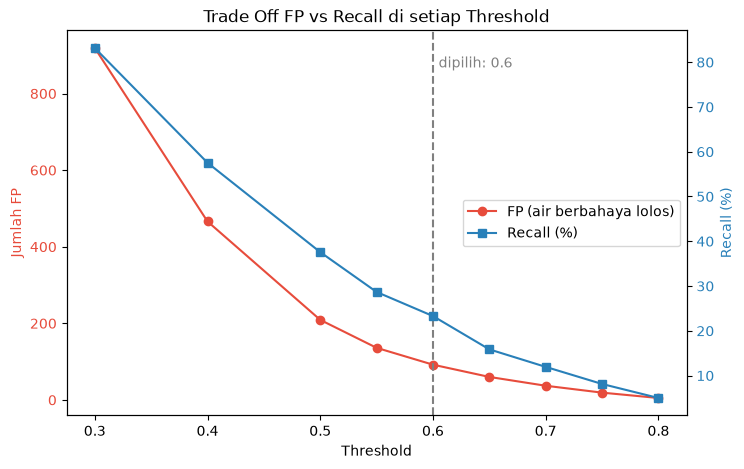

In [16]:
fig, ax1 = plt.subplots(figsize=(8, 5))

ax1.plot(thresh_df["Threshold"], thresh_df["FP"], "o-", color="#e74c3c", label="FP (air berbahaya lolos)")
ax1.set_xlabel("Threshold")
ax1.set_ylabel("Jumlah FP", color="#e74c3c")
ax1.tick_params(axis="y", labelcolor="#e74c3c")

ax1b = ax1.twinx()  # sumbu y kedua untuk Recall
ax1b.plot(thresh_df["Threshold"], thresh_df["Recall"] * 100, "s-", color="#2980b9", label="Recall (%)")
ax1b.set_ylabel("Recall (%)", color="#2980b9")
ax1b.tick_params(axis="y", labelcolor="#2980b9")

ax1.axvline(CHOSEN_TH, color="gray", linestyle="--")
ax1.text(CHOSEN_TH + 0.005, ax1.get_ylim()[1] * 0.9, f"dipilih: {CHOSEN_TH}", color="gray")
ax1.set_title("Trade Off FP vs Recall di setiap Threshold")

# gabungkan legend dari dua sumbu
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1b.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right")


##### Oke lanjut

In [17]:
final_model = make_pipeline(clone(preprocessor), clone(models[best_model_name]))
final_model.fit(X_train, y_train)

proba_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (proba_test >= opt_th).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print("Threshold:", opt_th)
print("ROC-AUC  :", round(roc_auc_score(y_test, proba_test), 4))
print("Accuracy :", round(accuracy_score(y_test, y_pred_test), 4))
print("Precision:", round(precision_score(y_test, y_pred_test, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_test), 4))
print("FP:", fp, "| FN:", fn, "| TP:", tp, "| TN:", tn)

Threshold: 0.6
ROC-AUC  : 0.6488
Accuracy : 0.6631
Precision: 0.6966
Recall   : 0.2422
FP: 27 | FN: 194 | TP: 62 | TN: 373


#### Part 4 : Permutation Importance pada Data Test

In [18]:
perm_imp = permutation_importance(
    final_model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE
)
imp_df = pd.DataFrame({
    "fitur": feature_cols,
    "importance_mean": perm_imp.importances_mean,
    "importance_std": perm_imp.importances_std,
}).sort_values(by="importance_mean", ascending=False)
print(imp_df)

             fitur  importance_mean  importance_std
4          Sulfate         0.087612        0.011887
0               ph         0.074339        0.010578
1         Hardness         0.049455        0.007150
2           Solids         0.042903        0.008758
3      Chloramines         0.027357        0.008668
6   Organic_carbon        -0.000423        0.008842
5     Conductivity        -0.007313        0.005810
7  Trihalomethanes        -0.008545        0.004730
8        Turbidity        -0.016045        0.006255


#### Part 5 : Simpan Model :)

In [19]:
joblib.dump(final_model, os.path.join(MODEL_DIR, "model_pipeline.joblib"))

['/home/krayza/Documents/Kuliah/Semester 5/Machine Learning/PJBL/PJBL di github/ML_Kelompok2_WaterPotability/model/model_pipeline.joblib']